In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [7]:
df = pd.read_csv('data.csv', sep=';')
df.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


In [8]:
df.shape

(4424, 37)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [10]:
# Check null values
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [11]:
# Transform categorical target variable into numeric format
df['Target'] = df['Target'].map({'Dropout': 0, 'Enrolled': 1, 'Graduate': 2})
df.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,0
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,2
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,0
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,2
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,2
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,2
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,2
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,0
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,2
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,0


In [12]:
class_counts = df['Target'].value_counts()
print(class_counts)

Target
2    2209
0    1421
1     794
Name: count, dtype: int64


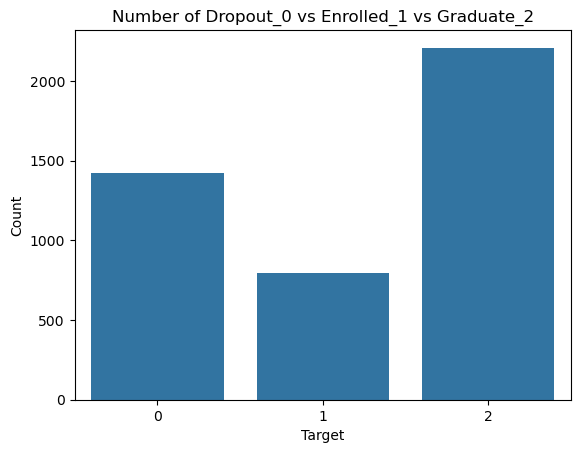

In [13]:
# Visualize Target column
sns.countplot(x = 'Target', data = df)
plt.title('Number of Dropout_0 vs Enrolled_1 vs Graduate_2')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

In [14]:
# Define features and target variable
X_raw = df.drop(columns='Target')
y = df['Target']
print(X_raw.shape, y.shape)

(4424, 36) (4424,)


In [15]:
# Feature Scaling to bring the variables in a single scale
sc = StandardScaler()
X = sc.fit_transform(X_raw)

In [16]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [17]:
# Split the data into training and testing sets (95% training, 5% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

results = []
for name, classifier in classifiers.items():
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    results.append([name, accuracy, precision, recall, f1_score])

results_df_5 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set (5%):")
results_df_5

(4202, 36) (222, 36) (4202,) (222,)


  File "C:\Users\NataliiaYurchenko\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\NataliiaYurchenko\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\NataliiaYurchenko\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\U

Model Performance Metrics on Test Set (5%):


,Model,Accuracy,Precision,Recall,F1 Score
0,k-Nearest Neighbors,0.752252,0.746101,0.752252,0.744109
1,Decision Tree,0.707207,0.705901,0.707207,0.706530
2,Random Forest,0.738739,0.719927,0.738739,0.719749
3,Logistic Regression,0.729730,0.707140,0.729730,0.706955
4,Support Vector Machine,0.747748,0.736286,0.747748,0.727537


In [27]:
# Split the data into training and testing sets (85% training, 15% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

results = []
for name, classifier in classifiers.items():
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    results.append([name, accuracy, precision, recall, f1_score])

results_df_15 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set (15%):")
results_df_15

(3760, 36) (664, 36) (3760,) (664,)
Model Performance Metrics on Test Set (15%):


,Model,Accuracy,Precision,Recall,F1 Score
0,k-Nearest Neighbors,0.706325,0.701968,0.706325,0.699153
1,Decision Tree,0.674699,0.686026,0.674699,0.679119
2,Random Forest,0.757530,0.741408,0.757530,0.742035
3,Logistic Regression,0.750000,0.727904,0.750000,0.733046
4,Support Vector Machine,0.745482,0.733737,0.745482,0.733888


In [18]:
# Split the data into training and testing sets (75% training, 25% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

results = []
for name, classifier in classifiers.items():
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    results.append([name, accuracy, precision, recall, f1_score])

results_df_25 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set (25%):")
results_df_25

(3318, 36) (1106, 36) (3318,) (1106,)
Model Performance Metrics on Test Set (25%):


,Model,Accuracy,Precision,Recall,F1 Score
0,k-Nearest Neighbors,0.697107,0.683180,0.697107,0.684807
1,Decision Tree,0.681736,0.686955,0.681736,0.683909
2,Random Forest,0.772152,0.755932,0.772152,0.756684
3,Logistic Regression,0.755877,0.735092,0.755877,0.738920
4,Support Vector Machine,0.755877,0.739632,0.755877,0.741338


In [19]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
cv_results_df


Cross-Validation Accuracy Scores:


,Model,Mean CV Accuracy
0,k-Nearest Neighbors,0.701624
1,Decision Tree,0.679251
2,Random Forest,0.775992
3,Logistic Regression,0.766271
4,Support Vector Machine,0.767175


In [20]:
# Define hyperparameter grids for each classifier
param_grids = {
    "k-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9]
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5, 10]
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20]
    },
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "solver": ['lbfgs', 'liblinear'],
        "penalty": ['l2']
    },
    "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ['linear', 'rbf']
    }
}

In [21]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for k-Nearest Neighbors...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running GridSearchCV for Decision Tree...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Running GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Running GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [22]:
# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
for row in results:
    print(row[0], "-> Accuracy:", round(row[1], 4), "| Best Parameters:", row[5])
results_df

Model Performance Metrics on Test Set after GridSearchCV:
k-Nearest Neighbors -> Accuracy: 0.7116 | Best Parameters: {'n_neighbors': 9}
Decision Tree -> Accuracy: 0.7405 | Best Parameters: {'max_depth': 5, 'min_samples_split': 10}
Random Forest -> Accuracy: 0.7722 | Best Parameters: {'max_depth': None, 'n_estimators': 100}
Logistic Regression -> Accuracy: 0.7541 | Best Parameters: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Support Vector Machine -> Accuracy: 0.7495 | Best Parameters: {'C': 0.1, 'kernel': 'linear'}


,Model,Accuracy,Precision,Recall,F1 Score,Best Parameters
0,k-Nearest Neighbors,0.711573,0.691164,0.711573,0.685408,{'n_neighbors': 9}
1,Decision Tree,0.740506,0.729787,0.740506,0.722878,"{'max_depth': 5, 'min_samples_split': 10}"
2,Random Forest,0.772152,0.755932,0.772152,0.756684,"{'max_depth': None, 'n_estimators': 100}"
3,Logistic Regression,0.754069,0.732675,0.754069,0.736876,"{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}"
4,Support Vector Machine,0.749548,0.734889,0.749548,0.735241,"{'C': 0.1, 'kernel': 'linear'}"


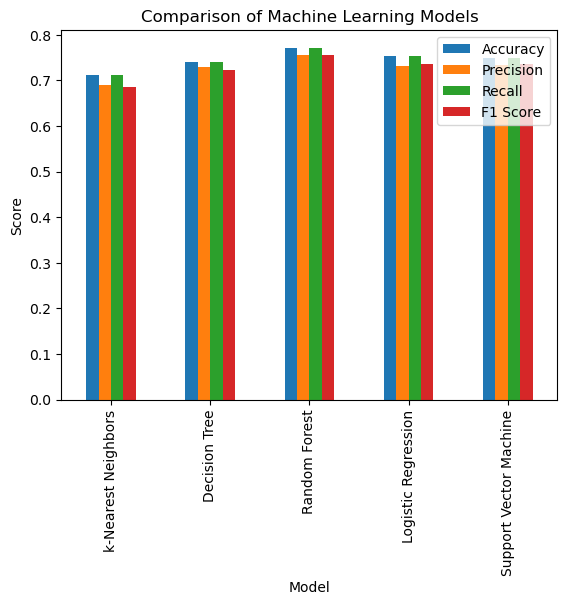

In [23]:
# Plot model comparison after GridSearchCV
results_df.plot(x = 'Model', y = ['Accuracy', 'Precision', 'Recall', 'F1 Score'], kind = 'bar')
plt.title('Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.show()

In [24]:
# Finding important features using Random Forest
clf_RF = RandomForestClassifier(n_estimators = 100, random_state = 42)
clf_RF.fit(X_train, y_train)
y_pred = clf_RF.predict(X_test)

feature_imp = pd.Series(clf_RF.feature_importances_, index = X_raw.columns).sort_values(ascending = False)
feature_imp.head(10)

Curricular units 2nd sem (approved)       0.140815
Curricular units 2nd sem (grade)          0.108781
Curricular units 1st sem (approved)       0.092758
Curricular units 1st sem (grade)          0.064748
Admission grade                           0.041752
Curricular units 2nd sem (evaluations)    0.041355
Tuition fees up to date                   0.040016
Previous qualification (grade)            0.038200
Curricular units 1st sem (evaluations)    0.037755
Age at enrollment                         0.036715
dtype: float64

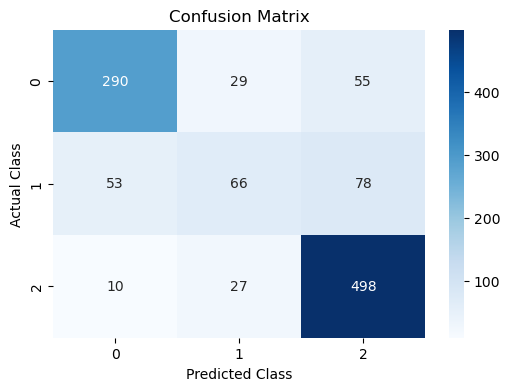

In [25]:
# Calculate and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [26]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.78      0.80       374
           1       0.54      0.34      0.41       197
           2       0.79      0.93      0.85       535

    accuracy                           0.77      1106
   macro avg       0.72      0.68      0.69      1106
weighted avg       0.76      0.77      0.76      1106

